# Chapitre 5 - Exercices 5.1 à 5.6

Ce notebook traite six exercices sur les fondements de l'ingénierie des prompts (cours 1 et 2) :

- **5.1** : combien coûte un prompt ? (calcul de coût mensuel, part des exemples, leviers d'économie) ;
- **5.2** : combien d'exemples ? rendement marginal du few-shot et choix de $k$ optimal ;
- **5.3** : calibration contextuelle, corriger les biais d'un prompt few-shot (mini-lab) ;
- **5.4** : réécrire le gabarit ChatML à la main et débusquer un gabarit bogué ;
- **5.5** : budget de contexte : cache KV, mémoire GPU et nombre de requêtes simultanées (calcul) ;
- **5.6** : « perdu au milieu » : test statistique et remède par la position de la question.

In [1]:
import time
import math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from aie import llm
from aie import ch05_prompts as P
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN,
                          LIGHT, annotate_bars, subtitle, finish)

set_style()
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 90)
tok = P._tokenizer(llm.SMALL)
pool, test = P.split_intents(4, seed=0)
y_true = [y for _, y in test]

## Exercice 5.1 : Combien coûte un prompt ?

**Énoncé.** Un assistant de service client reçoit **2 millions de requêtes par mois**. Chaque
requête contient : un prompt système de 400 tokens, 6 exemples de 60 tokens chacun, un message
utilisateur de 80 tokens en moyenne ; la réponse fait 150 tokens en moyenne. Tarifs de l'API :
2,50 \$ par million de tokens d'entrée et 10 \$ par million de tokens de sortie.

1. Calculer le coût mensuel et la part due aux exemples.
2. Évaluer trois leviers : (a) passer à 2 exemples ; (b) un format d'exemples 30 % plus compact ;
   (c) une **mise en cache du préfixe** (système + exemples, identiques pour toutes les requêtes)
   facturée à 50 % du prix normal ; (d) demander des réponses deux fois plus courtes.
3. Vérifier l'ordre de grandeur « 60 tokens par exemple » avec le tokenizer de Qwen sur les
   exemples du cours.

**Rappels.** Le coût d'un appel est linéaire en tokens d'entrée et de sortie :
$C = n_\text{in} c_\text{in} + n_\text{out} c_\text{out}$, et tout ce qui est dans le prompt
(système, exemples) est payé **à chaque requête** (section *In-Context Learning*, cours 1). Les
tokens de sortie coûtent typiquement 3 à 5 fois plus cher que ceux d'entrée.

**Solution.**

1. Entrée par requête : $400 + 6 \times 60 + 80 = 840$ tokens, soit $840 \times 2{,}5 \cdot 10^{-6}
   = 0{,}0021$ \$ ; sortie : $150 \times 10^{-5} = 0{,}0015$ \$. Total : $0{,}0036$ \$ par requête, donc
   **7 200 \$ par mois**. Les exemples (360 tokens) coûtent $360 \times 2{,}5\cdot10^{-6} \times 2\cdot10^6 = 1\,800$ \$,
   soit **25 %** de la facture.
2. Chaque levier se calcule de la même façon (code ci-dessous). Le cache du préfixe agit sur
   760 tokens par requête ; réduire la sortie agit sur le poste le plus cher par token.

In [2]:
def cout_mensuel(n_sys=400, n_ex=6, tok_ex=60, n_user=80, n_out=150, req=2e6, c_in=2.5e-6, c_out=10e-6,
                 remise_cache=0.0):
    prefixe = n_sys + n_ex * tok_ex
    entree = prefixe * (1 - remise_cache) + n_user
    postes = {"système": n_sys * (1 - remise_cache) * c_in * req,
              "exemples": n_ex * tok_ex * (1 - remise_cache) * c_in * req,
              "message utilisateur": n_user * c_in * req,
              "réponse": n_out * c_out * req}
    return postes

scen = {
    "référence": cout_mensuel(),
    "(a) 2 exemples": cout_mensuel(n_ex=2),
    "(b) format -30 %": cout_mensuel(tok_ex=42),
    "(c) cache du préfixe": cout_mensuel(remise_cache=0.5),
    "(d) réponses /2": cout_mensuel(n_out=75),
}
tab = pd.DataFrame(scen).T
tab["total"] = tab.sum(axis=1)
tab["économie"] = (1 - tab.total / tab.total["référence"]).map(lambda v: f"{100 * v:.0f} %")
tab.round(0)

,système,exemples,message utilisateur,réponse,total,économie
référence,2000.0,1800.0,400.0,3000.0,7200.0,0 %
(a) 2 exemples,2000.0,600.0,400.0,3000.0,6000.0,17 %
(b) format -30 %,2000.0,1260.0,400.0,3000.0,6660.0,7 %
(c) cache du préfixe,1000.0,900.0,400.0,3000.0,5300.0,26 %
(d) réponses /2,2000.0,1800.0,400.0,1500.0,5700.0,21 %


**Vérification** graphique et mesure de la taille réelle d'un exemple.

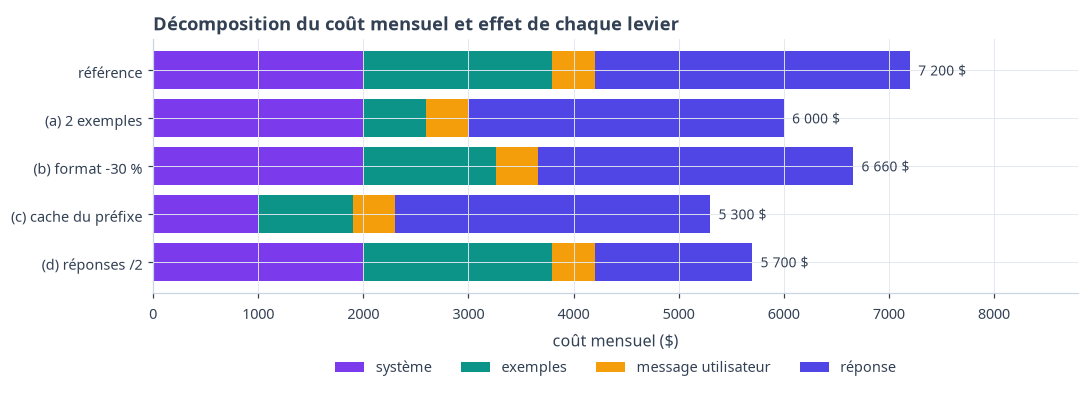

exemples du cours : 22.9 tokens en moyenne (min 17, max 29)
en tours de conversation, + ~10 tokens de gabarit par exemple (2 messages x ~5 tokens)


In [3]:
fig, ax = plt.subplots(figsize=(10, 3.8))
left = np.zeros(len(tab))
for col, c in zip(["système", "exemples", "message utilisateur", "réponse"], [VIOLET, TEAL, AMBER, INDIGO]):
    ax.barh(tab.index, tab[col], left=left, color=c, label=col)
    left += tab[col].values
for i, t in enumerate(tab.total):
    ax.text(t + 80, i, f"{t:,.0f} $".replace(",", " "), va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 8800)
ax.set_xlabel("coût mensuel ($)")
ax.set_title("Décomposition du coût mensuel et effet de chaque levier")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4)
finish(fig)
plt.show()

ex_tokens = [P.count_tokens(f"Message : {x}\nCatégorie : {y}") for x, y in pool]
print(f"exemples du cours : {np.mean(ex_tokens):.1f} tokens en moyenne (min {min(ex_tokens)}, max {max(ex_tokens)})")
print(f"en tours de conversation, + ~{2 * 5} tokens de gabarit par exemple (2 messages x ~5 tokens)")

Nos exemples de classification sont courts (une vingtaine de tokens) ; 60 tokens correspond à
des exemples plus riches (un ticket et sa réponse type). Le calcul montre que **la réponse**
est ici le premier poste : demander de la concision (cours 3, section 1) rapporte autant que
d'optimiser les exemples. Le cache de préfixe, proposé par plusieurs fournisseurs, rend les
longs préfixes stables (système + exemples) beaucoup moins chers : raison de plus pour mettre
les parties fixes **au début** du prompt.

> **À retenir.** Tout ce qui est fixe dans le prompt est payé à chaque appel ; un calcul de
> coût poste par poste indique quel levier actionner (nombre d'exemples, format, cache, longueur
> des réponses).

## Exercice 5.2 : Combien d'exemples ? Rendement marginal du few-shot

**Énoncé.** Sur la tâche d'intentions, mesurer la précision moyenne pour
$k \in \{0, 2, 4, 8, 16\}$ (exemples en tours de conversation, 3 tirages par $k$). Ajuster un
modèle de saturation $\text{acc}(k) = a - b\,e^{-k/\tau}$. On suppose qu'une bonne
classification rapporte 0,002 \$ (ticket bien routé) et qu'un exemple coûte 30 tokens d'entrée
à 2,5 \$ par million. Quel $k$ maximise le gain net par requête ? Que se passe-t-il si une
erreur coûte beaucoup plus cher ?

**Rappels.** L'apprentissage en contexte améliore la précision avec des rendements
décroissants (cours 1, section 3) ; chaque exemple augmente le coût linéairement
(exercice 5.1). Le gain net par requête vaut $G(k) = g\,\text{acc}(k) - k\,t\,c_\text{in}$.

**Solution.** On mesure la courbe, on l'ajuste par moindres carrés non linéaires, puis on
maximise $G(k)$ sur une grille. La dérivée $G'(k) = g\,\frac{b}{\tau} e^{-k/\tau} - t\,c_\text{in}$
s'annule en $k^\star = \tau \ln\!\big(\frac{g\,b}{\tau\,t\,c_\text{in}}\big)$ : $k^\star$ croît
**logarithmiquement** avec la valeur d'une bonne réponse.

In [4]:
from scipy.optimize import curve_fit

ks = [0, 2, 4, 8, 16]
mes = []
for k in ks:
    for s in range(3 if k else 1):
        mes.append(dict(k=k, tirage=s, acc=P.accuracy_at_k(test, P.sample_shots(pool, k, seed=s))))
mes = pd.DataFrame(mes)
moy = mes.groupby("k").acc.mean()

def sat(k, a, b, tau):
    return a - b * np.exp(-k / tau)

(a, b, tau), _ = curve_fit(sat, mes.k, mes.acc, p0=[0.75, 0.3, 4], bounds=([0, 0, 0.3], [1, 1, 50]))
print(f"ajustement : a = {a:.3f}, b = {b:.3f}, tau = {tau:.2f}")
moy.round(3)

ajustement : a = 0.731, b = 0.251, tau = 4.86


k
0     0.475
2     0.567
4     0.625
8     0.675
16    0.725
Name: acc, dtype: float64

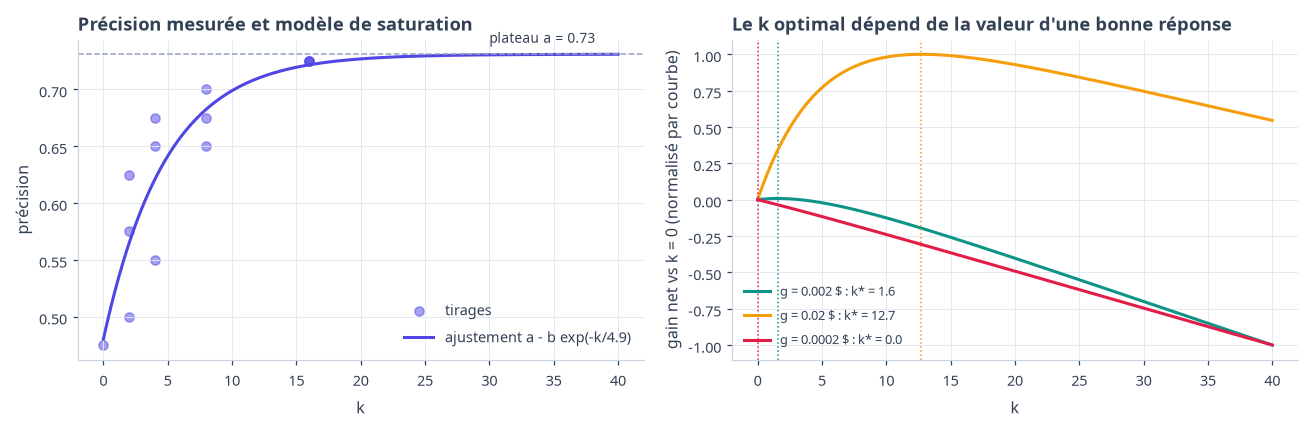

In [5]:
kk = np.linspace(0, 40, 401)
t_ex, c_in = 30, 2.5e-6
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.scatter(mes.k, mes.acc, color=INDIGO, alpha=0.5, label="tirages")
ax.plot(kk, sat(kk, a, b, tau), color=INDIGO, label=f"ajustement a - b exp(-k/{tau:.1f})")
ax.axhline(a, color=GRAY, ls="--", lw=1)
ax.text(30, a + 0.01, f"plateau a = {a:.2f}", fontsize=9)
ax.set_xlabel("k")
ax.set_ylabel("précision")
ax.set_title("Précision mesurée et modèle de saturation")
ax.legend(loc="lower right")
ax = axes[1]
for g, c in [(0.002, TEAL), (0.02, AMBER), (0.0002, ROSE)]:
    G = g * sat(kk, a, b, tau) - kk * t_ex * c_in
    kstar = kk[np.argmax(G)]
    dG = G - G[0]
    ax.plot(kk, dG / np.abs(dG).max(), color=c, label=f"g = {g} $ : k* = {kstar:.1f}")
    ax.axvline(kstar, color=c, ls=":", lw=1)
ax.set_xlabel("k")
ax.set_ylabel("gain net vs k = 0 (normalisé par courbe)")
ax.set_title("Le k optimal dépend de la valeur d'une bonne réponse")
ax.legend(fontsize=8.5, loc="lower left")
finish(fig)
plt.show()

**Lecture.** Quand une bonne réponse vaut peu (0,0002 \$), quelques exemples suffisent, voire
aucun ; quand elle vaut cher (0,02 \$, par exemple une erreur de routage qui coûte un appel
humain), on a intérêt à aller jusqu'au plateau de la courbe. Attention : avec 40 messages de
test et 3 tirages, l'ajustement est bruité ; et au-delà de 16 exemples on **extrapole**.

> **À retenir.** Le nombre d'exemples se choisit par une analyse coût / bénéfice sur une courbe
> **mesurée** : $k^\star$ ne croît que logarithmiquement avec la valeur d'une bonne réponse.

## Exercice 5.3 : Calibration contextuelle

**Énoncé.** Au cours 1, la présentation « en ligne » des exemples rendait le modèle instable et
biaisé vers certaines étiquettes. Zhao et al. (2021) proposent la **calibration contextuelle** :
on mesure les probabilités que le prompt attribue aux étiquettes pour une entrée **vide de
sens** (« N/A », chaîne vide, « [MASK] »), puis on divise les probabilités de chaque vraie
entrée par ce biais. Implémenter la méthode et mesurer son effet sur 5 ordres d'un même jeu de
8 exemples.

**Rappels.** Biais de récence et d'étiquette majoritaire (cours 1, section 4). Si $\hat p(y\mid x)$
est la distribution du modèle et $\bar p_\text{cf}(y)$ la moyenne des distributions sur les entrées
vides, la prédiction calibrée est
$$\tilde y = \arg\max_y \frac{\hat p(y\mid x)}{\bar p_\text{cf}(y)},$$
c'est-à-dire une transformation affine diagonale $W = \mathrm{diag}(\bar p_\text{cf})^{-1}$
appliquée aux probabilités, puis renormalisation.

**Solution.** Pour un prompt donné (exemples et ordre fixés), on calcule $\bar p_\text{cf}$
(3 appels), puis on corrige chaque prédiction. Le coût est négligeable : 3 appels par prompt.

In [6]:
base8 = P.sample_shots(pool, 8, seed=2)
rng = np.random.default_rng(0)
CONTENT_FREE = ["N/A", "", "[MASK]"]
rows = []
for perm_id in range(5):
    perm = list(range(8)) if perm_id == 0 else list(rng.permutation(8))
    shots = [base8[j] for j in perm]
    p_cf = np.mean([P.classify(cf, shots, shot_format="inline")[1] for cf in CONTENT_FREE], axis=0)
    labs, probs = P.predictions(test, shots, shot_format="inline")
    cal = probs / p_cf
    cal = cal / cal.sum(axis=1, keepdims=True)
    pred_cal = [P.INTENT_LABELS[i] for i in cal.argmax(1)]
    rows.append(dict(ordre=perm_id, biais_cf=np.round(p_cf, 2), avant=np.mean([a == b for a, b in zip(labs, y_true)]),
                     apres=np.mean([a == b for a, b in zip(pred_cal, y_true)]),
                     etiquettes_distinctes_avant=len(set(labs)), etiquettes_distinctes_apres=len(set(pred_cal))))
calib = pd.DataFrame(rows)
calib

,ordre,biais_cf,avant,apres,etiquettes_distinctes_avant,etiquettes_distinctes_apres
0,0,"[0.21, 0.48, 0.14, 0.18]",0.250,0.325,1,4
1,1,"[0.41, 0.13, 0.05, 0.41]",0.500,0.450,3,4
2,2,"[0.42, 0.15, 0.12, 0.3]",0.525,0.500,3,4
3,3,"[0.2, 0.65, 0.04, 0.12]",0.350,0.375,3,4
4,4,"[0.33, 0.25, 0.11, 0.31]",0.450,0.475,3,4


**Vérification** graphique.

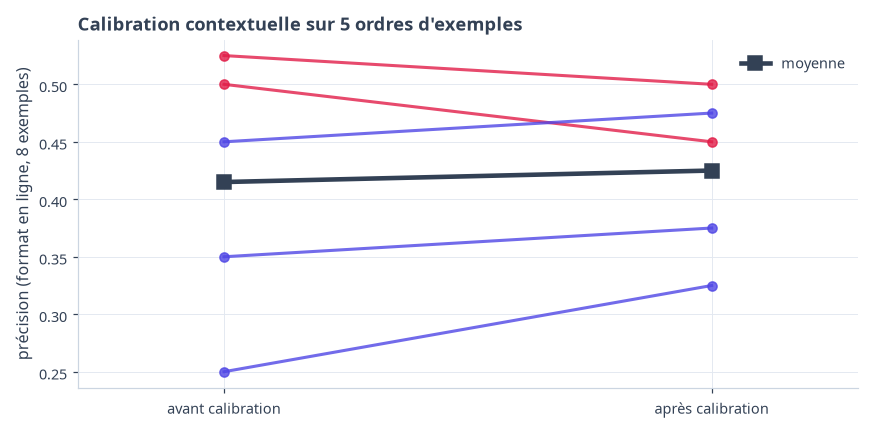

précision moyenne : 0.415 -> 0.425 ; écart-type entre ordres : 0.114 -> 0.073


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
for i, r in calib.iterrows():
    ax.plot([0, 1], [r.avant, r.apres], "-o", color=INDIGO if r.apres >= r.avant else ROSE, alpha=0.8)
ax.plot([0, 1], [calib.avant.mean(), calib.apres.mean()], "-s", color=SLATE, lw=3, ms=9, label="moyenne")
ax.set_xticks([0, 1], ["avant calibration", "après calibration"])
ax.set_xlim(-0.3, 1.3)
ax.set_ylabel("précision (format en ligne, 8 exemples)")
ax.set_title("Calibration contextuelle sur 5 ordres d'exemples")
ax.legend()
finish(fig)
plt.show()
print(f"précision moyenne : {calib.avant.mean():.3f} -> {calib.apres.mean():.3f} ; "
      f"écart-type entre ordres : {calib.avant.std():.3f} -> {calib.apres.std():.3f}")

**Lecture.** La colonne `biais_cf` montre que, pour une entrée vide de sens, le prompt penche
nettement vers une ou deux étiquettes : c'est le biais que la calibration retire. Après
correction, le modèle utilise davantage d'étiquettes distinctes ; selon l'ordre, la précision
progresse plus ou moins, et peut parfois baisser (le biais mesuré sur « N/A » n'est qu'une
approximation du biais réel). La méthode ne remplace pas une meilleure présentation (les tours
de conversation du cours 1), mais elle est gratuite et réduit la sensibilité au prompt.

> **À retenir.** Un prompt few-shot induit un biais a priori sur les étiquettes, mesurable avec
> une entrée vide de sens et corrigeable par une simple division : 3 appels pour un prompt plus
> stable.